In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

Parameter Dataset

In [ ]:
BATCHSIZE = 32
LG_IMGSIZE = (256, 256)
SM_IMGSIZE = (32, 32)

dataDir = tf.keras.preprocessing.image_dataset_from_directory(
    "/content/drive/MyDrive/TugasAI/data",
    batch_size = BATCHSIZE,
    image_size = LG_IMGSIZE,
)

Found 4188 files belonging to 4 classes.


In [ ]:
classNames = dataDir.class_names
classNames

['Blight', 'Common_Rust', 'Gray_Leaf_Spot', 'Healthy']

Tampilkan Gambar

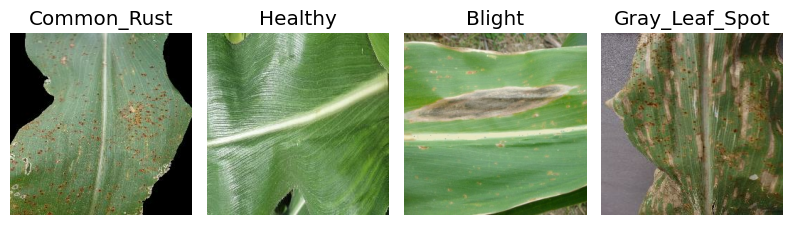

In [ ]:
import matplotlib.pyplot as plt
images_per_class = {}

for images, labels in dataDir.take(1):
    for img, label in zip(images, labels):
        class_name = classNames[label.numpy()]
        if class_name not in images_per_class:
            images_per_class[class_name] = img
        if len(images_per_class) == len(classNames):
            break

plt.figure(figsize=(10, 10))
for i, (class_name, img) in enumerate(images_per_class.items()):
    ax = plt.subplot(3, 5, i + 1)
    plt.imshow(img.numpy().astype("uint8"))
    plt.title(class_name, fontsize='x-large', fontweight='ultralight')
    plt.axis("off")
plt.tight_layout()
plt.show()


Training, Validasi, Testing

In [ ]:
trainDS = tf.keras.utils.image_dataset_from_directory(
    "/content/drive/MyDrive/TugasAI/data",
    batch_size = BATCHSIZE,
    image_size = SM_IMGSIZE,
    subset="training",
    seed=123,
    validation_split=0.2,
    shuffle=True
)

validDS = tf.keras.utils.image_dataset_from_directory(
    "/content/drive/MyDrive/TugasAI/data",
    batch_size = BATCHSIZE,
    image_size = SM_IMGSIZE,
    subset="validation",
    seed=123,
    validation_split=0.2,
    shuffle=True
)

testDS = tf.keras.utils.image_dataset_from_directory(
    "/content/drive/MyDrive/TugasAI/data",
    batch_size = BATCHSIZE,
    image_size = SM_IMGSIZE,
    seed=123,
    shuffle=True

)

Found 4188 files belonging to 4 classes.
Using 3351 files for training.
Found 4188 files belonging to 4 classes.
Using 837 files for validation.
Found 4188 files belonging to 4 classes.


Model CNN

In [ ]:
model = models.Sequential()
model.add(layers.Rescaling(1./255, input_shape=(32,32,3)))
model.add(layers.Conv2D(32, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))

/usr/local/lib/python3.10/dist-packages/keras/src/layers/preprocessing/tf_data_layer.py:19: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
model.summary()
Model: "sequential"

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)                │ (None, 32, 32, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 30, 30, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 15, 15, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 13, 13, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 6, 6, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 4, 4, 64)            │          36,928 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 56,320 (220.00 KB)

 Trainable params: 56,320 (220.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.add(layers.Flatten())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(4))
model.summary()
Model: "sequential"

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)                │ (None, 32, 32, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 30, 30, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 15, 15, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 13, 13, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 6, 6, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 4, 4, 64)            │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1024)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │          65,600 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 4)                   │             260 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 122,180 (477.27 KB)

 Trainable params: 122,180 (477.27 KB)

 Non-trainable params: 0 (0.00 B)

Latih Model

In [ ]:
model.compile(optimizer='adam', loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=['accuracy'])

history = model.fit(trainDS, epochs=30,
                   validation_data=(validDS))

Epoch 1/30
105/105 ━━━━━━━━━━━━━━━━━━━━ 381s 4s/step - accuracy: 0.5184 - loss: 1.0776 - val_accuracy: 0.7455 - val_loss: 0.6461
Epoch 2/30
105/105 ━━━━━━━━━━━━━━━━━━━━ 27s 206ms/step - accuracy: 0.7724 - loss: 0.5417 - val_accuracy: 0.8136 - val_loss: 0.4614
Epoch 3/30
105/105 ━━━━━━━━━━━━━━━━━━━━ 40s 196ms/step - accuracy: 0.8180 - loss: 0.4367 - val_accuracy: 0.8076 - val_loss: 0.4266
Epoch 4/30
105/105 ━━━━━━━━━━━━━━━━━━━━ 23s 216ms/step - accuracy: 0.8370 - loss: 0.4009 - val_accuracy: 0.8363 - val_loss: 0.3837
Epoch 5/30
105/105 ━━━━━━━━━━━━━━━━━━━━ 41s 216ms/step - accuracy: 0.8512 - loss: 0.3653 - val_accuracy: 0.8315 - val_loss: 0.3858
Epoch 6/30
105/105 ━━━━━━━━━━━━━━━━━━━━ 40s 205ms/step - accuracy: 0.8566 - loss: 0.3347 - val_accuracy: 0.8411 - val_loss: 0.3550
Epoch 7/30
105/105 ━━━━━━━━━━━━━━━━━━━━ 42s 216ms/step - accuracy: 0.8780 - loss: 0.2938 - val_accuracy: 0.8519 - val_loss: 0.3170
Epoch 8/30
105/105 ━━━━━━━━━━━━━━━━━━━━ 24s 227ms/step - accuracy: 0.8910 - loss: 0.2

Akurasi & Loss

In [ ]:
test_loss, test_accuracy = model.evaluate(testDS, verbose=2)

accuracy_percent = round(test_accuracy * 100)
loss_percent = round(test_loss * 100)

print(f"Test Loss     : {test_loss} ({loss_percent}%)")
print(f"Test Accuracy : {test_accuracy} ({accuracy_percent}%)")


131/131 - 18s - 138ms/step - accuracy: 0.9670 - loss: 0.1357
Test Loss     : 0.13567595183849335 (14%)
Test Accuracy : 0.967048704624176 (97%)


Plot

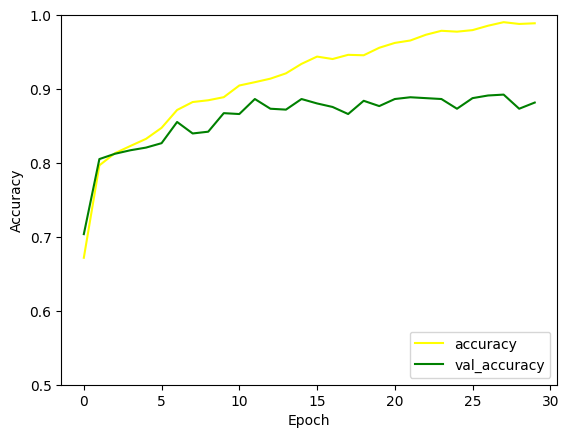

In [ ]:
plt.plot(history.history['accuracy'], label='accuracy', color='yellow')
plt.plot(history.history['val_accuracy'], label='val_accuracy', color='green')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.5, 1])
plt.legend(loc='lower right')

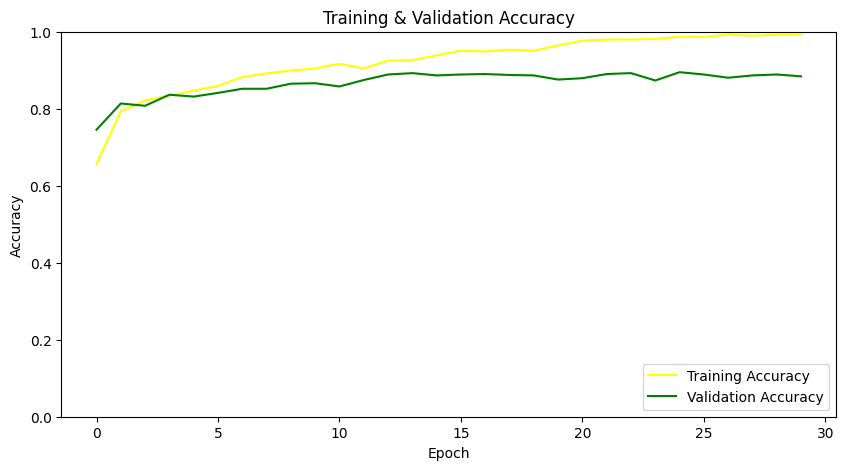

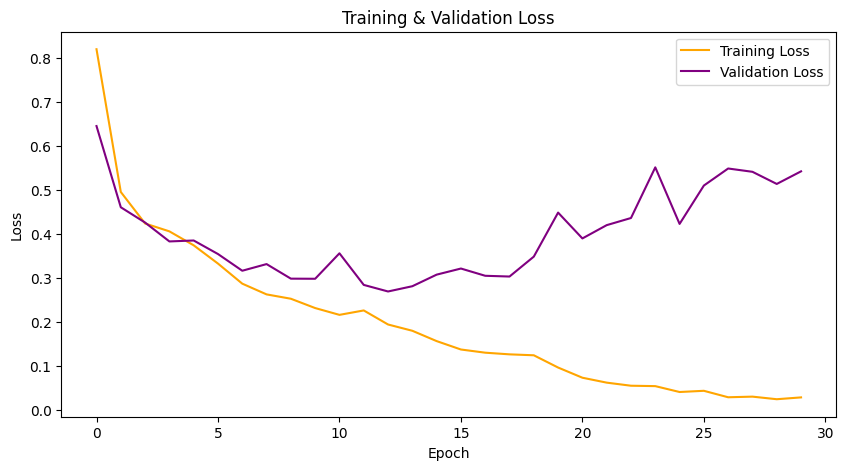

In [ ]:
import matplotlib.pyplot as plt

# Plot Training & Validation Accuracy
plt.figure(figsize=(10, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy', color='yellow')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', color='green')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1])
plt.title('Training & Validation Accuracy')
plt.legend(loc='lower right')
plt.show()

# Plot Training & Validation Loss
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Training Loss', color='orange')
plt.plot(history.history['val_loss'], label='Validation Loss', color='purple')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training & Validation Loss')
plt.legend(loc='upper right')
plt.show()


Evaluasi Klasifikasi

In [ ]:
yTrue = []
yPred = []

for images, labels in testDS:
    predictions = model.predict(images)
    predictClasses = np.argmax(predictions, axis=1)

    yTrue.extend(labels.numpy())
    yPred.extend(predictClasses)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 417ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━

In [ ]:
cr = classification_report(yTrue, yPred)
print(cr)

              precision    recall  f1-score   support

           0       0.93      0.97      0.95      1146
           1       0.99      0.98      0.99      1306
           2       0.94      0.87      0.91       574
           3       0.98      1.00      0.99      1162

    accuracy                           0.97      4188
   macro avg       0.96      0.96      0.96      4188
weighted avg       0.97      0.97      0.97      4188



Masukkan Hasil ke GDrive

In [25]:
from google.colab import drive
import os
import shutil
drive.mount('/content/drive')

gdrive_folder = '/content/drive/MyDrive/TugasAI/Hasil_DaunJagung'
if not os.path.exists(gdrive_folder):
    os.makedirs(gdrive_folder)
local_folder = "hasilModel"

if not os.path.exists(local_folder):
    os.makedirs(local_folder)

output_text = f"""
Test Loss     : {test_loss:.4f} ({loss_percent}%)
Test Accuracy : {test_accuracy:.4f} ({accuracy_percent}%)

Classification Report:
{classification_report(yTrue, yPred)}
"""
with open(os.path.join(local_folder, "hasil.txt"), "w") as file:
    file.write(output_text)

import json
report_dict = classification_report(yTrue, yPred, output_dict=True)
with open(os.path.join(local_folder, "klasifikasi_report.json"), "w") as json_file:
    json.dump(report_dict, json_file, indent=4)

plt.plot(history.history['accuracy'], label='accuracy', color='yellow')
plt.plot(history.history['val_accuracy'], label='val_accuracy', color='green')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.5, 1])
plt.legend(loc='lower right')
plt.savefig(os.path.join(local_folder, "akurasi_plot.png"))
plt.close()

plt.plot(history.history['loss'], label='loss', color='blue')
plt.plot(history.history['val_loss'], label='val_loss', color='red')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.savefig(os.path.join(local_folder, "loss_plot.png"))
plt.close()

model.save(os.path.join(local_folder, "latih_model.h5"))

for i, (class_name, img) in enumerate(images_per_class.items()):
    plt.imshow(img.numpy().astype("uint8"))
    plt.title(class_name, fontsize='x-large', fontweight='ultralight')
    plt.axis("off")
    plt.savefig(os.path.join(local_folder, f"class_{class_name}.png"))
    plt.close()
zip_file = "hasilModel.zip"
shutil.make_archive(local_folder, 'zip', local_folder)
shutil.move(f"{local_folder}.zip", os.path.join(gdrive_folder, zip_file))

print(f"File ZIP hasil tersimpan di Google Drive: {os.path.join(gdrive_folder, zip_file)}")



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


File ZIP hasil tersimpan di Google Drive: /content/drive/MyDrive/TugasAI/Hasil_DaunJagung/hasilModel.zip


In [27]:
model.save('/content/drive/MyDrive/TugasAI/Hasil_DaunJagung/FinalModel.h5')
print("Model saved as FinalModel.h5")


Model saved as FinalModel.h5
